# DriveMatch — AI Car Recommendation Model
### Human–Machine Interface (HMI) university project · Egyptian vehicle market

This executable notebook builds the **same TF-IDF content-based ML model** used by the DriveMatch website, tests the ranking system, and exports a trained artifact for the **FastAPI** backend.

**Algorithm:** unsupervised text vectorization (TF-IDF n-grams) + cosine similarity + interpretable weighted suitability scoring. This is **not** a supervised model trained on real Egyptian buyers, nor a generative chatbot.

**Dataset disclaimer:** 64 example car records; prices and numeric ratings are illustrative and not current dealer quotes.

## 1 — Setup and import libraries
Run the notebook from the project root, the `notebooks` folder, or inside Jupyter. For dependencies: `py -m pip install -r backend/requirements.txt notebook matplotlib pandas` (or install the corresponding packages in your notebook kernel).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

cwd = Path.cwd()
project = next((p for p in [cwd, cwd.parent, cwd / 'egypt-car-match'] if (p / 'backend' / 'cars.json').exists()), None)
if project is None:
    raise FileNotFoundError('Open this notebook from the DriveMatch project root or notebooks/ folder.')
backend = project / 'backend'
cars = json.loads((backend / 'cars.json').read_text(encoding='utf-8'))
df = pd.DataFrame(cars)
print(f'Dataset size: {len(df)} cars, {df.brand.nunique()} brands')
display(df[['brand','model','type','price','seats','fuel','transmission']].head(10))

Dataset size: 64 cars, 24 brands


,brand,model,type,price,seats,fuel,transmission
0,Nissan,Sunny,Sedan,780000,5,Petrol,Automatic
1,Chery,Arrizo 5,Sedan,700000,5,Petrol,Automatic
2,Chevrolet,Optra,Sedan,735000,5,Petrol,Automatic
3,MG,5,Sedan,900000,5,Petrol,Automatic
4,MG,ZS,SUV,1100000,5,Petrol,Automatic
5,Hyundai,Elantra AD,Sedan,1050000,5,Petrol,Automatic
6,Toyota,Corolla,Sedan,1450000,5,Petrol,Automatic
7,Nissan,Qashqai,SUV,1650000,5,Petrol,Automatic
8,Hyundai,Tucson,SUV,1950000,5,Petrol,Automatic
9,Chery,Tiggo 7 Pro,SUV,1350000,5,Petrol,Automatic


## 2 — Exploratory analysis
Inspect category mix and demo EGP price ranges before building the recommendation engine.

,cars,median_demo_price_egp
type,,
SUV,34,1680000.0
Sedan,21,890000.0
Hatchback,9,1080000.0


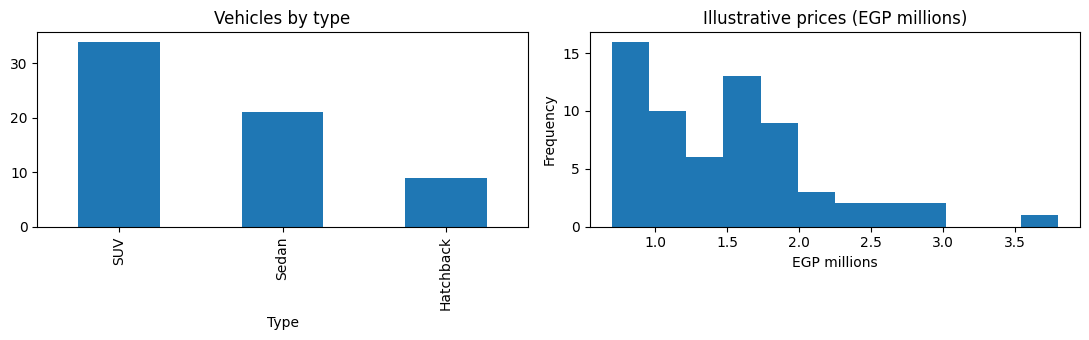

In [2]:
display(df.groupby('type').agg(cars=('id','count'), median_demo_price_egp=('price','median')).sort_values('cars',ascending=False))
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
df['type'].value_counts().plot(kind='bar',ax=axes[0],title='Vehicles by type')
(df['price']/1_000_000).plot(kind='hist',bins=12,ax=axes[1],title='Illustrative prices (EGP millions)')
axes[0].set_xlabel('Type'); axes[1].set_xlabel('EGP millions')
plt.tight_layout();plt.show()

## 3 — Train an unsupervised TF-IDF model
Each car is described using its category, lifestyle tags, and description. The model learns a vocabulary and represents each vehicle as a sparse vector. No externally labeled purchases are available.

In [3]:
documents = [f"{c['type']} {' '.join(c['tags'])} {c['description']}" for c in cars]
vectorizer = TfidfVectorizer(ngram_range=(1,2), stop_words='english')
car_vectors = vectorizer.fit_transform(documents)
print('TF-IDF matrix:',car_vectors.shape)
print('Learned vocabulary size:',len(vectorizer.vocabulary_))
print('Example terms:',list(vectorizer.get_feature_names_out())[:25])

TF-IDF matrix: (64, 516)
Learned vocabulary size: 516
Example terms: ['7seat', '7seat crossover', '7seat highway', '7seat large', 'active', 'active families', 'adaptable', 'adaptable passenger', 'affordable', 'affordable ownership', 'affordable sedan', 'alsvin', 'alsvin sedan', 'atto', 'atto suv', 'body', 'body frame', 'budget', 'budget family', 'budget features', 'budget friendly', 'budget value', 'busy', 'busy families', 'buying']


## 4 — Explainable car-ranking algorithm
The code below deliberately matches `backend/main.py`: hard filters enforce budget, seats, fuel and gearbox, then weighted ranking balances semantic similarity and practical suitability.

In [4]:
def recommend(preferences, top_k=6):
    p = {
        'budget':1_200_000,'passengers':4,'usage':'mixed','priority':'economy',
        'roads':'normal','parking':'normal','transmission':'Any','fuel':'Any','notes':''
    }
    p.update(preferences)
    intent_parts = [p['usage'],p['priority'],p['roads'],
                    'family' if p['passengers']>=5 else 'commute',p['notes']]
    intent=' '.join(intent_parts).replace('rough','weekend crossover SUV')
    semantic=cosine_similarity(vectorizer.transform([intent]),car_vectors).flatten()
    weights={'city':{'city':1.0,'highway':0.1},
             'mixed':{'city':0.5,'highway':0.5},
             'highway':{'city':0.1,'highway':1.0}}[p['usage']]
    results=[]
    for i,car in enumerate(cars):
        if car['price']>p['budget'] or car['seats']<p['passengers']:continue
        if p['transmission']!='Any' and car['transmission']!=p['transmission']:continue
        if p['fuel']!='Any' and car['fuel']!=p['fuel']:continue
        drive=(car['city']*weights['city']+car['highway']*weights['highway'])/10
        priority=car[p['priority']]/10
        terrain=(car['rough'] if p['roads']=='rough' else car['comfort'])/10
        parking=(car['parking'] if p['parking']=='easy' else car['comfort'])/10
        value=max(0,min(1,1-car['price']/p['budget']))
        score=(.28*priority+.22*drive+.13*terrain+.10*parking+
               .17*float(semantic[i])+.10*value)
        results.append({**car,'score':round(score*100),'similarity':round(float(semantic[i]),3)})
    return sorted(results,key=lambda c:(-c['score'],c['price']))[:top_k]

scenario={'budget':1_200_000,'passengers':4,'usage':'city','priority':'economy','parking':'easy'}
display(pd.DataFrame(recommend(scenario))[['brand','model','price','score','similarity']])

,brand,model,price,score,similarity
0,Mitsubishi,Attrage,770000,74,0.193
1,Suzuki,Dzire,825000,73,0.358
2,Dongfeng,BOX,900000,73,0.036
3,Mitsubishi,Mirage,790000,72,0.075
4,Suzuki,Swift,850000,71,0.152
5,Hyundai,i10,780000,67,0.082


## 5 — Evaluate behavior with scenario-based tests
Without real user-choice labels, precision/recall would be misleading. Instead we validate **hard constraints**, deterministic ranking, and practical scenario coverage. These are functional tests, not evidence of prediction accuracy.

In [5]:
scenarios = {
    'City commuter':{'budget':1_000_000,'usage':'city','priority':'economy','parking':'easy'},
    'Family travel':{'budget':2_500_000,'passengers':5,'usage':'highway','priority':'family'},
    'Rough roads':{'budget':2_000_000,'passengers':4,'roads':'rough','priority':'comfort'},
    'Low budget':{'budget':650_000,'passengers':2,'priority':'economy'},
    'Hybrid':{'budget':3_000_000,'fuel':'Hybrid','priority':'economy'}
}
report=[]
for name,p in scenarios.items():
    results=recommend(p)
    assert all(c['price']<=p['budget'] for c in results)
    assert all(c['seats']>=p.get('passengers',4) for c in results)
    assert all(c['fuel']==p.get('fuel','Any') for c in results) if p.get('fuel','Any')!='Any' else True
    assert all(results[j]['score']>=results[j+1]['score'] for j in range(len(results)-1))
    report.append({'scenario':name,'matches':len(results),'top_match':f"{results[0]['brand']} {results[0]['model']}" if results else 'None within constraints','top_score':results[0]['score'] if results else None})
display(pd.DataFrame(report))
print('All constraint and ranking tests passed.')

,scenario,matches,top_match,top_score
0,City commuter,6,Mitsubishi Attrage,72.0
1,Family travel,6,Nissan Qashqai,74.0
2,Rough roads,6,Hyundai Tucson,67.0
3,Low budget,0,None within constraints,NaN
4,Hybrid,3,BYD Song Plus,68.0


All constraint and ranking tests passed.


## 6 — Export trained ML artifact for the live website
Running this cell creates `backend/models/car_tfidf.joblib`. The FastAPI server uses this file automatically when it matches the current car dataset. Restart the backend after exporting. The backend can also refit the same model at startup if no artifact is present.

In [6]:
model_dir=backend/'models'
model_dir.mkdir(exist_ok=True)
artifact_path=model_dir/'car_tfidf.joblib'
artifact={'vectorizer':vectorizer,'car_vectors':car_vectors,
          'car_ids':[str(c['id']) for c in cars],'documents':documents,
          'algorithm':'TF-IDF (1,2) + cosine similarity + weighted suitability',
          'note':'Educational content-based model; no supervised labels'}
joblib.dump(artifact,artifact_path)
reloaded=joblib.load(artifact_path)
assert reloaded['car_vectors'].shape==car_vectors.shape
print('Saved model to:',artifact_path)
print('Restart backend and check GET http://localhost:8000/api/health for model_source.')

Saved model to: /mnt/data/drivematch_upgrade/egypt-car-match/backend/models/car_tfidf.joblib
Restart backend and check GET http://localhost:8000/api/health for model_source.


## 7 — How the notebook connects to the website

1. **Jupyter notebook** fits TF-IDF on `backend/cars.json` and exports `backend/models/car_tfidf.joblib`.
2. **FastAPI** loads the exported artifact at startup (and safely refits if missing/stale).
3. **React** sends user preferences to `POST /api/recommend`.
4. **Backend** uses cosine similarity and weighted scores to return up to six eligible cars, with explanations.
5. **React** displays cards with photos, prices and match percentages.

**Limitations and future work:** Prices and suitability ratings are estimates; photo searches can show different trims/years; the 64-car dataset is small; there are no labeled real-world user selections to evaluate predictive quality. For a future study, gather consented preference→choice examples and evaluate a supervised ranker against this baseline.